In [1]:
pip install hotspotsc scanpy

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 8.8 MB/s eta 0:00:00ta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.0/129.0 kB 8.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.5/73.5 kB 5.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 114.3 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 64.7 MB/s eta 0:00:00:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 24.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 128.8 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 53.4 MB/s eta 0:00:0000:0100:01m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.8/91.8 kB 9.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 321.9/321.9 kB 27.4 MB/s eta 0:

# How it works

Hotspot (the hotspotsc package) does two things. It finds genes with significant spatial autocorrelation, which gives Moran's-I-style spatial DE. It then groups those genes into modules that share a spatial pattern.


In [1]:
import numpy as np, pandas as pd, scanpy as sc, hotspot

adata = sc.read_h5ad("/data/projects/punim1236/liver_curio/2026714RCTDnew/bin20/Y01453J8_tissue_bin20_raw_counts.h5ad")
adata.layers["counts"] = adata.X.copy()
adata.obsm["spatial"] = adata.obs[["x", "y"]].to_numpy()
adata.obs["total_counts"] = np.asarray(adata.layers["counts"].sum(1)).ravel()

# keep expressed genes only; this matters a lot for speed
sc.pp.filter_genes(adata, min_cells=int(0.01 * adata.n_obs))

/home/oskinner/.local/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/oskinner/.local/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


# Hotspot

Hotspot uses nearest neighbours rather than a radius. n_neighbors=30 covers roughly 3 spot-widths on a square grid. Smaller values (10 to 15) find fine structure like, and larger ones (50 or more) find broad tissue zones. Run two values and compare the modules.

In [2]:
hs = hotspot.Hotspot(
    adata,
    layer_key="counts",
    model="danb",                   # depth-adjusted negative binomial; suits counts
    latent_obsm_key="spatial",      # build the graph from x/y coordinates
    umi_counts_obs_key="total_counts",
)

hs.create_knn_graph(weighted_graph=False, n_neighbors=15)

hs_results = hs.compute_autocorrelations(jobs=8)
hs_results.sort_values("Z", ascending=False).head(20)   # C, Z, Pval, FDR per gene

/home/oskinner/.local/lib/python3.9/site-packages/hotspot/hotspot.py:98: UserWarning: Hotspot will work faster when counts are a csr sparse matrix.
  warnings.warn(
100%|██████████| 3467/3467 [03:51<00:00, 14.97it/s]


,C,Z,Pval,FDR
Gene,,,,
Gm42418,0.477215,813.077882,0.0,0.0
Gphn,0.369749,714.257467,0.0,0.0
Cmss1,0.371637,680.038563,0.0,0.0
Saa2,0.468654,637.529745,0.0,0.0
Alb,0.450528,632.810663,0.0,0.0
Saa1,0.372943,533.122018,0.0,0.0
Camk1d,0.231095,431.845832,0.0,0.0
Lars2,0.178456,303.020972,0.0,0.0
AY036118,0.150321,257.893699,0.0,0.0


Computing pair-wise local correlation on 500 features...


100%|██████████| 124750/124750 [1:01:57<00:00, 33.56it/s]


Computing scores for 6 modules...


100%|██████████| 6/6 [00:13<00:00,  2.17s/it]


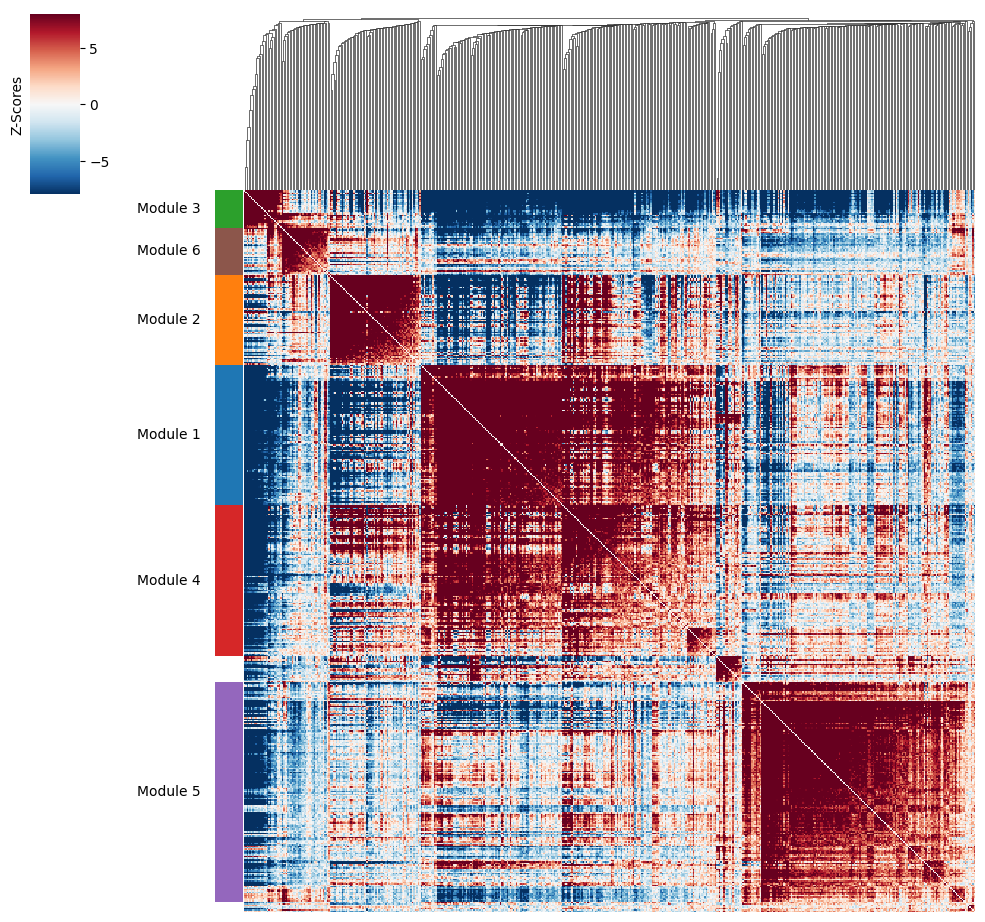

In [3]:
# find modules of gens sharing spatial pattern, restrict to the top genes: pairwise correlations are the expensive step
top_genes = hs_results.loc[hs_results.FDR < 0.05].sort_values("Z", ascending=False).head(500).index

hs.compute_local_correlations(top_genes, jobs=8)

modules = hs.create_modules(min_gene_threshold=20, core_only=False, fdr_threshold=0.05)
modules.value_counts()          # -1 = gene not assigned to a module

hs.plot_local_correlations()    # gene-gene correlation heatmap with module bars

module_scores = hs.calculate_module_scores()   # spots x modules
adata.obs[module_scores.columns] = module_scores

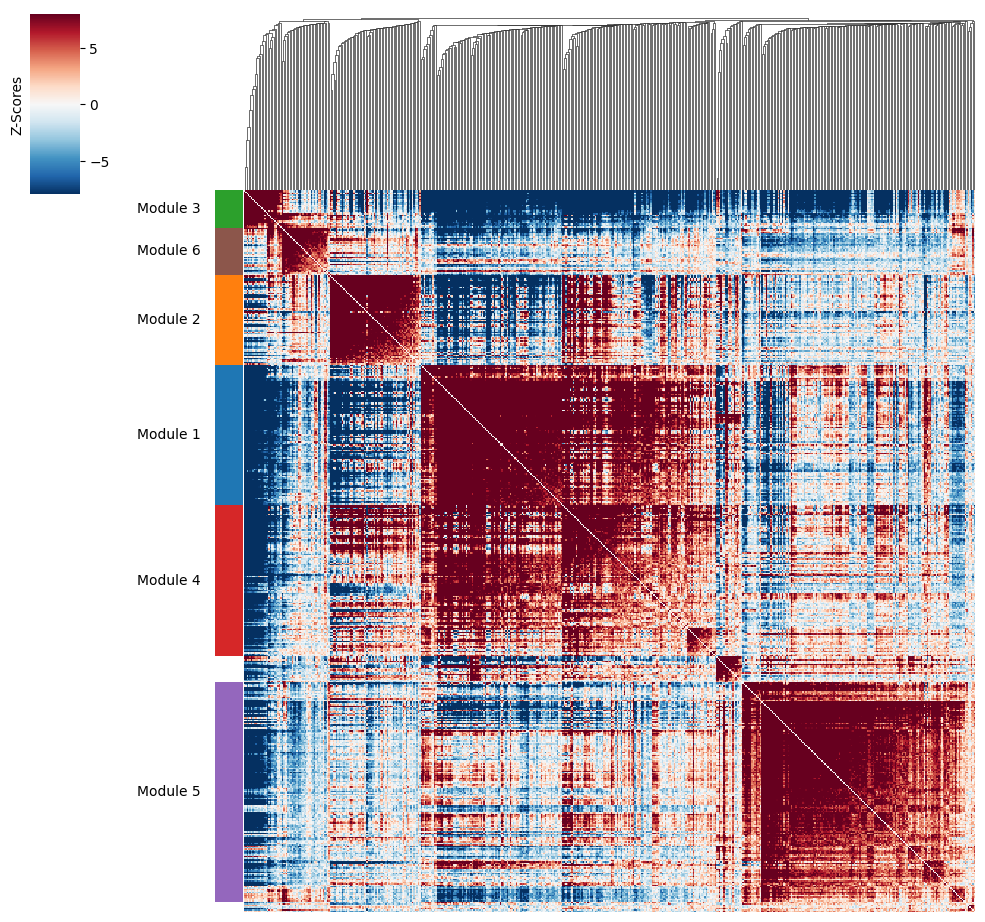

In [20]:
import os
import matplotlib.pyplot as plt

outdir = "hotspot_plots"
os.makedirs(outdir, exist_ok=True)

hs.plot_local_correlations()                      # redraws the heatmap; this is quick
plt.savefig(os.path.join(outdir, "local_correlations.pdf"), bbox_inches="tight")
plt.savefig(os.path.join(outdir, "local_correlations.png"), dpi=300, bbox_inches="tight")

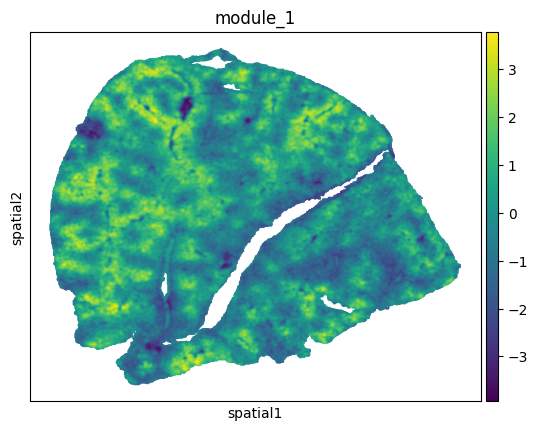

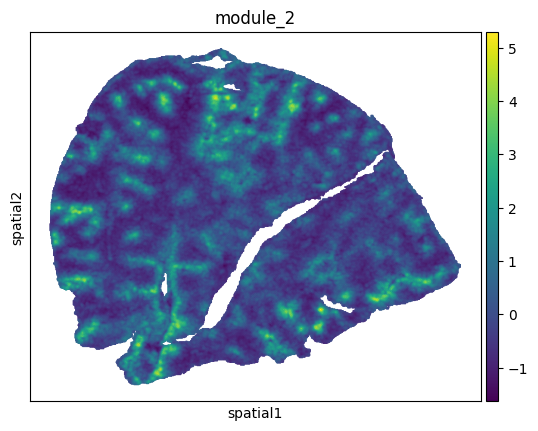

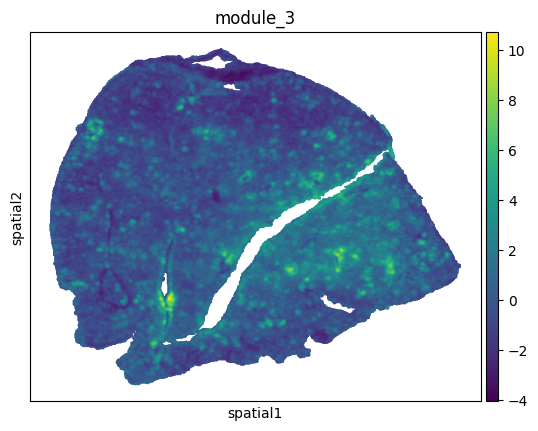

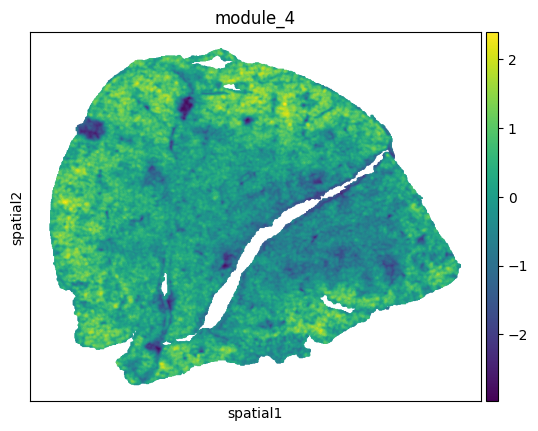

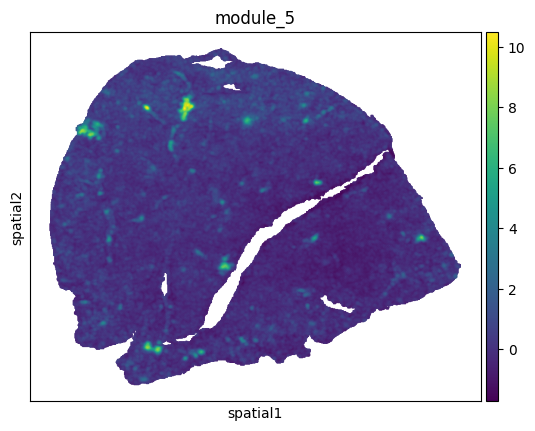

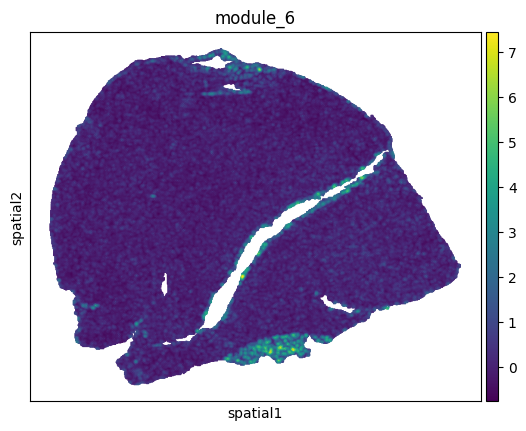

In [5]:
import matplotlib.pyplot as plt

# remove any integer-named columns added earlier
adata.obs = adata.obs.drop(columns=[c for c in adata.obs.columns if not isinstance(c, str)])

# rename module columns to strings and add them to obs
module_scores.columns = [f"module_{m}" for m in module_scores.columns]
adata.obs[module_scores.columns] = module_scores

for m in module_scores.columns:
    sc.pl.embedding(adata, basis="spatial", color=m, size=3, cmap="viridis", title=m)

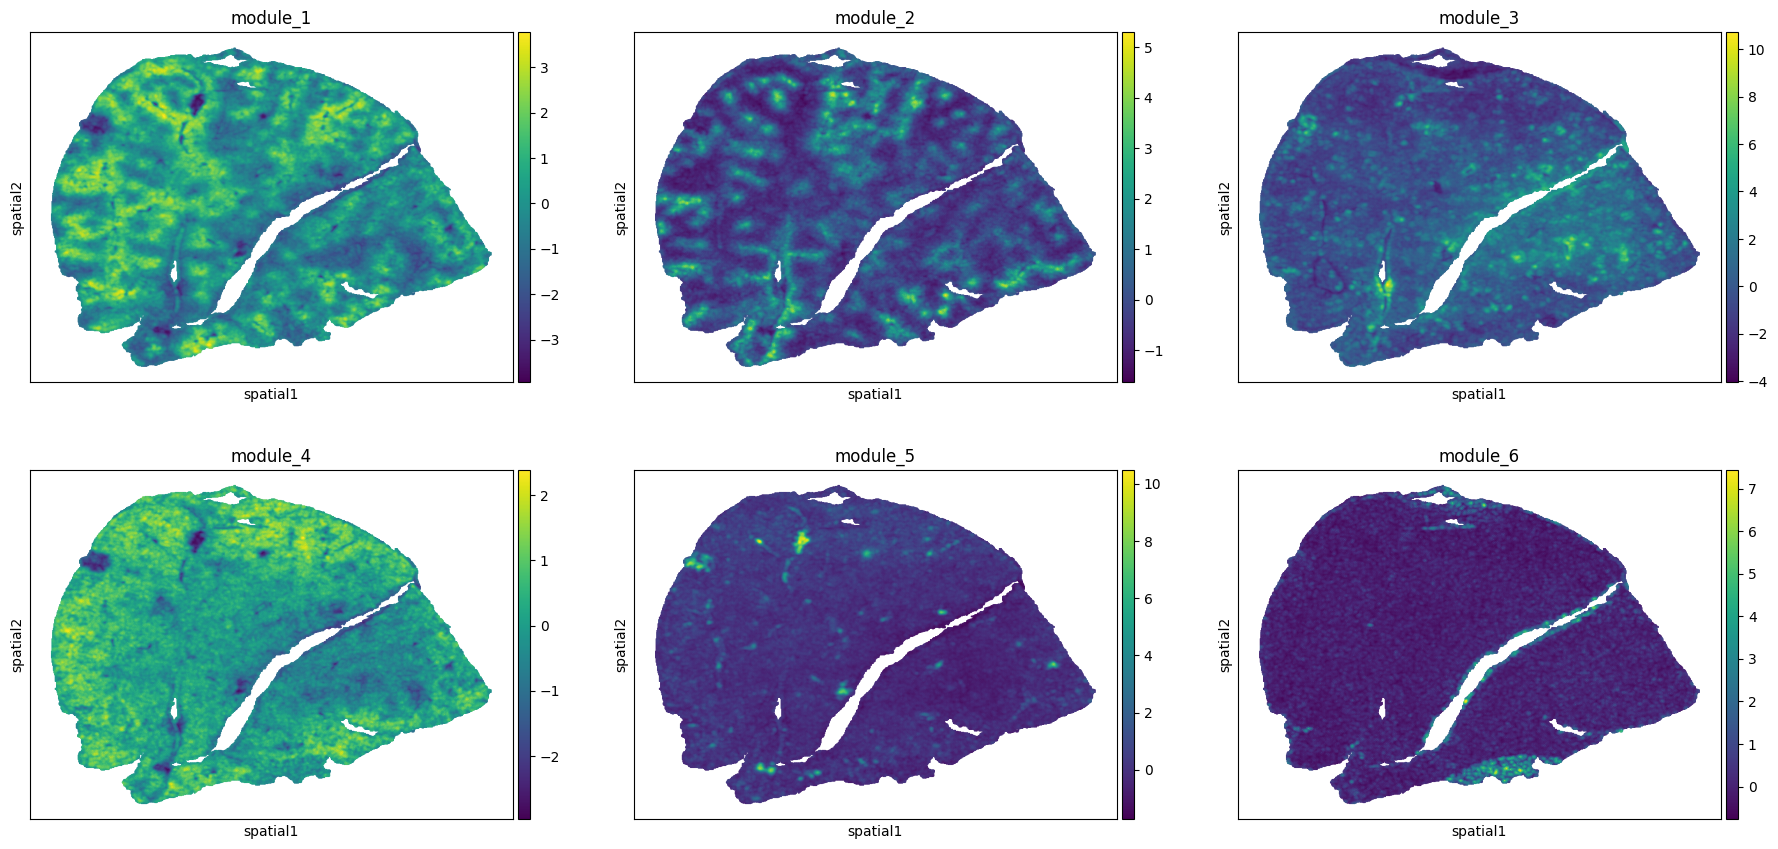

In [6]:
sc.pl.embedding(adata, basis="spatial", color=list(module_scores.columns),
                size=3, cmap="viridis", ncols=3)

In [15]:
import os

print(os.getcwd())                       # where you are now
os.chdir("/data/projects/punim1236/liver_stomicsv1.3/hotspot/")
print(os.getcwd())                       # confirm it changed

/data/gpfs/projects/punim1236/liver_stomicsv1.3/hotspot
/data/gpfs/projects/punim1236/liver_stomicsv1.3/hotspot


In [19]:
import os
import matplotlib.pyplot as plt

outdir = "hotspot_plots"      # relative to your working directory, or use a full path
os.makedirs(outdir, exist_ok=True)

# remove any integer-named columns added earlier
adata.obs = adata.obs.drop(columns=[c for c in adata.obs.columns if not isinstance(c, str)])

# rename module columns to strings and add them to obs
module_scores.columns = [f"module_{m}" for m in module_scores.columns]
adata.obs[module_scores.columns] = module_scores

for m in module_scores.columns:
    ax = sc.pl.embedding(adata, basis="spatial", color=m, size=1, cmap="viridis",
                         title=m, show=False)
    ax.set_aspect("equal", adjustable="box")
    plt.savefig(os.path.join(outdir, f"{m}.png"), dpi=300, bbox_inches="tight")
    plt.close()

# Module gene marker

This information is used to assess the function of eahc module - i.e. can we pick up granuloma modules

In [22]:
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp

outdir = "hotspot_plots"
os.makedirs(outdir, exist_ok=True)

# ---- 1) genes per module, ranked by autocorrelation Z ----
mod_df = pd.DataFrame({"gene": modules.index, "module": modules.values})
mod_df = mod_df[mod_df["module"] != -1]
mod_df = mod_df.merge(hs_results[["C", "Z", "FDR"]],
                      left_on="gene", right_index=True, how="left")
mod_df = mod_df.sort_values(["module", "Z"], ascending=[True, False])
mod_df.to_csv(os.path.join(outdir, "hotspot_module_genes.csv"), index=False)

# ---- 2) rank by correlation with each module's score ----
depth = adata.obs["total_counts"].values
rows = []

for m in sorted(mod_df["module"].unique()):
    genes = mod_df.loc[mod_df["module"] == m, "gene"].tolist()

    X = adata[:, genes].layers["counts"]
    X = X.toarray() if sp.issparse(X) else np.asarray(X)
    X = np.log1p(X / depth[:, None] * 1e4).astype("float32")

    s = adata.obs[f"module_{m}"].values.astype("float32")

    Xz = (X - X.mean(0)) / X.std(0)
    sz = (s - s.mean()) / s.std()
    r  = Xz.T @ sz / len(s)

    rows.append(pd.DataFrame({"gene": genes, "module": m, "corr_with_module": r}))

mod_df2 = mod_df.merge(pd.concat(rows), on=["gene", "module"]).sort_values(
    ["module", "corr_with_module"], ascending=[True, False])

mod_df2.to_csv(os.path.join(outdir, "hotspot_module_genes_ranked.csv"), index=False)
mod_df2.groupby("module").head(20).to_csv(
    os.path.join(outdir, "hotspot_module_top20_ranked.csv"), index=False)

# one csv and one plain gene list per module (the .txt files paste straight into Enrichr or g:Profiler)
for m, g in mod_df2.groupby("module"):
    g.to_csv(os.path.join(outdir, f"module_{m}_genes.csv"), index=False)
    g["gene"].to_csv(os.path.join(outdir, f"module_{m}_genelist.txt"),
                     index=False, header=False)

print(mod_df2.groupby("module").head(10).groupby("module")["gene"].apply(list))

module
1    [Alb, Hpx, Trf, Selenop, Gc, Rida, Kng1, Cyp2a...
2    [Glul, Cyp2e1, Oat, Cyp2a5, Slc1a2, Gulo, Cyp1...
3    [Gm42418, Cmss1, Gphn, Camk1d, Lars2, Gm19951,...
4    [Apoa2, Apoe, Gm20425, Ttr, Apoc1, Fabp1, Apoa...
5    [Tmsb4x, Lyz2, H2-Aa, Cd74, Actb, H2-Ab1, Psap...
6    [Gm26917, Malat1, Celf2, Sox5, Lrmda, Xist, Im...
Name: gene, dtype: object


In [23]:
import os
import pandas as pd

outdir = "hotspot_results"
os.makedirs(outdir, exist_ok=True)

# gene-level results and module assignments
hs_results.to_csv(os.path.join(outdir, "hotspot_autocorrelation.csv"))
modules.to_csv(os.path.join(outdir, "hotspot_modules.csv"))

# gene-by-gene correlation z-scores (needed to redraw the heatmap or re-cut modules)
hs.local_correlation_z.to_csv(os.path.join(outdir, "hotspot_local_correlation_z.csv"))

# module scores per spot
module_scores.to_csv(os.path.join(outdir, "hotspot_module_scores.csv"))

In [24]:
adata.var["hotspot_module"] = modules.reindex(adata.var_names).fillna(-1).astype(int).values   # -1 = unassigned
adata.var = adata.var.join(hs_results[["C", "Z", "Pval", "FDR"]].add_prefix("hotspot_"), how="left")

adata.write_h5ad(os.path.join(outdir, "adata_with_hotspot.h5ad"))

# Save and extract the coordinates and module scores so can merge it as metadata with R object

In [28]:
import re

# make the names clean again: strip every repeated prefix, then add one
module_scores.columns = ["module_" + re.sub(r"^(module_)+", "", str(c)) for c in module_scores.columns]

# drop every module-looking column from adata.obs, then add the clean ones back
old = [c for c in adata.obs.columns if re.fullmatch(r"(module_)+\d+", str(c))]
adata.obs = adata.obs.drop(columns=old)
adata.obs[module_scores.columns] = module_scores

print([c for c in adata.obs.columns if "module" in c])   # should show module_1 ... module_6 only

['module_1', 'module_2', 'module_3', 'module_4', 'module_5', 'module_6']


In [29]:
import os
import pandas as pd

outdir = "hotspot_results"
os.makedirs(outdir, exist_ok=True)

mod_cols = [c for c in adata.obs.columns if c.startswith("module_")]

out = pd.DataFrame(adata.obsm["spatial"], index=adata.obs_names.astype(str), columns=["x", "y"])
out = pd.concat([out, adata.obs.loc[:, mod_cols]], axis=1)
out.index.name = "barcode"
out.to_csv(os.path.join(outdir, "hotspot_spot_scores.csv"))

# gene-to-module table for the same run
gene_tab = pd.DataFrame({"gene": modules.index, "module": modules.values}).merge(
    hs_results[["C", "Z", "FDR"]], left_on="gene", right_index=True, how="left")
gene_tab.to_csv(os.path.join(outdir, "hotspot_gene_modules.csv"), index=False)
